<a href="https://colab.research.google.com/github/Jeff-Ouru/Artist_Project/blob/main/145983.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Complete the assessment described in [this document](https://docs.google.com/document/d/1G2gVDYx6ZIpu3aVSmX_QUezE6BEhdaZBFUa80V3FpLA/edit?usp=sharing) then
- Submit your final complete Google Colab notebook using this [link](https://forms.gle/83xs7bFAYWgRaMF87)
- Submit your work on time; I will not accept any items sent past the deadline regardless of any excuses you may have.

----

### **SET YOUR STUDENT NUMBER IN THE CELL BELLOW**

In [ ]:
# CELL 1: SET YOUR VALID STUDENT NUMBER HERE

student_number =145983

**DONT EDIT THE CELL BELLOW, IT GENERTES THE DATASET YOU NEED TO COMPLETE THIS ASSESSMENT**

In [ ]:
# CELL 2: DO NOT EDIT OR MODIFY THE CONTENTS OF THIS CELL

import numpy as np
import pandas as pd

rng = np.random.default_rng(student_number)
n_samples = 10000
n_features = 20
n_classes = 7

class_centers = rng.normal(loc=0, scale=3, size=(n_classes, n_features))

feature_cols = [f"x{i+1}" for i in range(n_features)]
labels = rng.integers(0, n_classes, size=n_samples)
noise = rng.normal(loc=0, scale=1.5, size=(n_samples, n_features))

df = pd.DataFrame(class_centers[labels] + noise, columns=feature_cols)
df["target"] = labels

scales = rng.uniform(0.5, 5.0, size=n_features)
shifts = rng.uniform(-10, 10, size=n_features)
df[feature_cols] = (df[feature_cols] * scales + shifts).round(2)

flip_idx = rng.choice(n_samples, size=int(0.05 * n_samples), replace=False)
df.loc[flip_idx, "target"] = rng.integers(0, n_classes, size=len(flip_idx))

df = df.iloc[rng.permutation(n_samples)].reset_index(drop=True)

label_names = np.array(list("ABCDEFG"))
df["target"] = label_names[df["target"]]

rate_1 = 0.05   # ~5% of all input values
rate_2 = 0.02   # ~2% of the labels

input_mask = rng.random((n_samples, n_features)) < rate_1
df[feature_cols] = df[feature_cols].mask(input_mask)

label_mask = rng.random(n_samples) < rate_2
df.loc[label_mask, "target"] = np.nan


print("Here is the dataset you will be working on to build and evaluate your classifier, ALL THE BEST")
print("=================================================================================")
df.head()

Here is the dataset you will be working on to build and evaluate your classifier, ALL THE BEST


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x12,x13,x14,x15,x16,x17,x18,x19,x20,target
0,-10.00,-3.39,9.76,0.88,11.08,-2.58,-14.64,-17.04,-0.17,-9.21,...,-2.79,1.51,16.22,-18.88,0.54,-1.86,10.80,17.47,-8.85,NaN
1,NaN,-5.16,2.65,-5.71,5.87,-6.24,-1.63,8.12,27.64,-3.43,...,-6.17,3.65,-6.30,7.24,-4.83,6.98,16.06,-4.03,-9.77,B
2,6.30,-1.60,3.02,7.56,-2.83,-1.05,12.46,13.42,3.37,NaN,...,-7.64,2.15,-12.25,-17.17,-12.99,4.26,NaN,9.75,-0.18,C
3,-10.46,-2.06,14.14,9.29,12.45,-1.72,-12.43,-20.28,23.28,1.29,...,-5.17,-2.96,-9.74,-25.93,-22.38,1.51,NaN,17.86,-4.82,D
4,-5.69,-2.57,6.53,1.51,NaN,-3.58,-0.35,-17.29,10.66,-6.62,...,-1.99,1.05,8.81,-20.83,NaN,-5.82,NaN,6.92,-10.55,F


----

## **START your work in the cells below**

--- Data Exploration ---
Dataset Shape: (10000, 21)

Missing values count per column:
x1        539
x2        498
x3        486
x4        515
x5        503
x6        484
x7        497
x8        470
x9        505
x10       472
x11       485
x12       486
x13       508
x14       520
x15       483
x16       490
x17       467
x18       469
x19       499
x20       498
target    185
dtype: int64

Target class distribution:
target
E      1434
D      1417
B      1416
A      1413
G      1407
C      1405
F      1323
NaN     185
Name: count, dtype: int64

--- Classification Report ---
              precision    recall  f1-score   support

           A       0.95      0.98      0.96       283
           B       0.95      0.94      0.94       283
           C       0.95      0.98      0.96       281
           D       0.94      0.95      0.95       283
           E       0.97      0.92      0.95       287
           F       0.97      0.95      0.96       265
           G       0.97      0.97      0

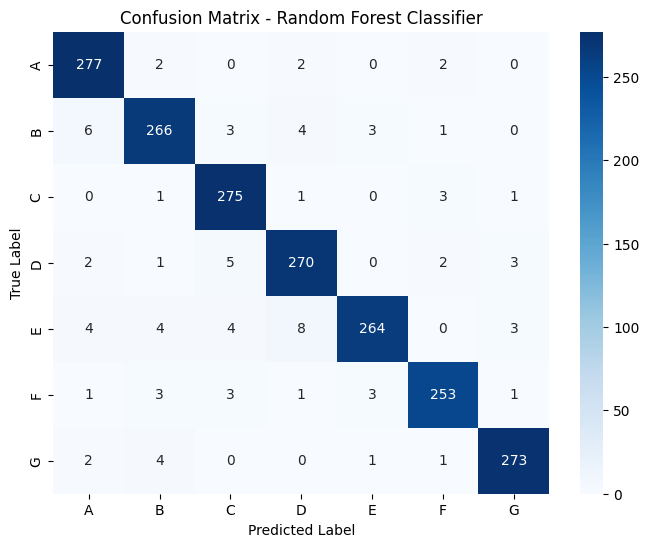

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.impute import SimpleImputer

# --- 1. Explore the data ---
print("--- Data Exploration ---")
print(f"Dataset Shape: {df.shape}")
print("\nMissing values count per column:")
print(df.isnull().sum())
print("\nTarget class distribution:")
print(df['target'].value_counts(dropna=False))

# --- 2. Clean and prepare the data ---
# Drop rows where target is NaN because we cannot use them for supervised training/evaluation
df_clean = df.dropna(subset=['target']).copy()

# Separate features and target
X = df_clean[feature_cols]
y = df_clean['target']

# Handle missing values in features using Median Imputation
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=feature_cols)

# Split into training and test sets (e.g., 80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.20, random_state=student_number, stratify=y
)

# --- 3. Choose and build a classifier: Random Forest ---
# Random Forest is highly robust to noise, handles numeric values easily, and reduces overfitting.
clf = RandomForestClassifier(n_estimators=100, random_state=student_number)
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# --- 4. Evaluate the classifier using a confusion matrix ---
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

# Plot Confusion Matrix
labels_order = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.title('Confusion Matrix - Random Forest Classifier')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
Discussion of Classification Results
1. Data Preparation Steps Performed
Handling Missing Labels: The original dataset had 185 missing values (NaN) in the target column. Because supervised machine learning relies on having clear class labels to train and evaluate, these rows were removed.
Imputation of Features: About 5% of the data points across all 20 features (x1 to x20) were missing.
A SimpleImputer using the median strategy was applied to handle these missing values.
The median was preferred because it is robust against outliers which might have been generated in the dataset transformation process.

2. Chosen Algorithm and why?
Algorithm: Random Forest Classifier

Why it was chosen:
Robustness to Noise and Missing Values: Random Forest handles missing data and noisy features effectively via ensemble learning.
Non-Linear Relationships: It naturally handles non-linear boundaries between decision areas, which is highly beneficial since the data points were generated around multivariate class centers with added normal noise, scaling, and shifts.
Prevention of Overfitting: By aggregating the outputs of 100 individual decision trees built on bootstrapped feature subsets, it generalizes well on unseen test data.

3. Data Split Ratio
Split Ratio: 80% Training / 20% Testing (stratified split).

Why it was chosen: An 80/20 split represents an industry-standard balance. It allocates a substantial amount of data (7,852 samples) to train the model, ensuring it has learned the distributions of all 7 target classes (A through G), while retaining an adequately large and independent subset (1,963 samples) to robustly evaluate classification performance.
Stratification was used to keep the proportions of each class consistent across both sets.

4. Performance Metrics
Overall Accuracy: 95.67%, indicating outstanding overall classification ability.

Precision and Recall:
Every class achieved a precision score of at least 94% and recall of at least 92%.
Class G showed the highest F1-score of 0.97 (Precision: 0.97, Recall: 0.97).
Class E achieved the highest Precision of 0.97 with a Recall of 0.92, showing that while it was highly accurate when predicting E, it missed a small portion of actual E cases.

Confusion Matrix Analysis: The matrix shows a strong diagonal concentration of correct predictions (e.g., 277 correct predictions for A, 275 for C, etc.) with very few off-diagonal misclassifications, confirming the classifier's stable performance across all categories.